# مشروع تحليل أرباح المبيعات

## 1. فهم المشكلة

يهدف هذا المشروع إلى تحليل بيانات المبيعات
والأرباح في متجر Superstore، لمعرفة أسباب
انخفاض الأرباح رغم ارتفاع حجم المبيعات.

## أهداف المشروع

- تحديد المنتجات الأكثر تحقيقًا للأرباح والخسائر.
- دراسة تأثير الخصومات على الأرباح.
- مقارنة أداء المبيعات بين المناطق المختلفة.
- اكتشاف أسباب الخسائر واقتراح حلول مناسبة.
- تصميم لوحة تحكم تفاعلية لعرض النتائج.

## سؤال العميل

لماذا تحقق بعض المنتجات مبيعات مرتفعة
ولكن أرباحها منخفضة أو تحقق خسائر؟

In [1]:
import pandas as pd

# قراءة بيانات المشروع مباشرة من GitHub
url = (
    "https://raw.githubusercontent.com/"
    "amadawi79-commits/"
    "superstore-profit-analysis/main/data/raw.csv"
)

df = pd.read_csv(url, encoding="latin1")

# التأكد من تحميل البيانات
print("عدد الصفوف:", df.shape[0])
print("عدد الأعمدة:", df.shape[1])

display(df.head())

عدد الصفوف: 9994
عدد الأعمدة: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [1]:
import pandas as pd

clean_url = "https://raw.githubusercontent.com/amadawi79-commits/superstore-profit-analysis/main/data/clean.csv"
clean_df = pd.read_csv(clean_url)

print("عدد الصفوف:", len(clean_df))
print("أسماء الأعمدة:", clean_df.columns.tolist())

عدد الصفوف: 9994
أسماء الأعمدة: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [ ]:
# فحص جودة بيانات المبيعات

print("عدد الصفوف المكررة:", df.duplicated().sum())

print("\nالقيم المفقودة في كل عمود:")
print(df.isnull().sum())

print("\nملخص المبيعات والأرباح والخصومات:")
display(df[["Sales", "Profit", "Discount"]].describe())

عدد الصفوف المكررة: 0

القيم المفقودة في كل عمود:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

ملخص المبيعات والأرباح والخصومات:


,Sales,Profit,Discount
count,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,0.156203
std,623.245101,234.260108,0.206452
min,0.444000,-6599.978000,0.000000
25%,17.280000,1.728750,0.000000
50%,54.490000,8.666500,0.200000
75%,209.940000,29.364000,0.200000
max,22638.480000,8399.976000,0.800000


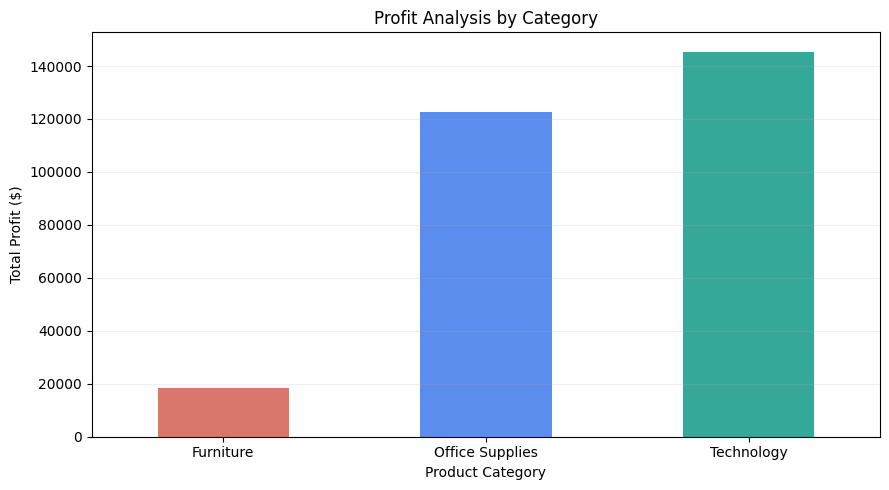

,Total Profit
Category,
Furniture,18451.2728
Office Supplies,122490.8008
Technology,145454.9481


In [ ]:
import matplotlib.pyplot as plt

# حساب إجمالي الأرباح حسب فئة المنتج
category_profit = df.groupby("Category")["Profit"].sum()
category_profit = category_profit.sort_values()

# إنشاء الرسم البياني
plt.figure(figsize=(9, 5))

category_profit.plot(
    kind="bar",
    color=["#D9776A", "#5B8DEF", "#36A89A"]
)

plt.title("Profit Analysis by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# عرض النتائج بالأرقام
display(category_profit.to_frame("Total Profit"))

## 2. التحليل الاستكشافي للبيانات (EDA)

### الاكتشاف الأول: تفاوت الأرباح بين فئات المنتجات

بعد تحليل إجمالي الأرباح حسب فئات المنتجات،
لاحظت أن فئة التكنولوجيا حققت أعلى ربح
بقيمة 145,454.95 دولار، تليها المستلزمات
المكتبية بقيمة 122,490.80 دولار.

أما فئة الأثاث فقد حققت أقل إجمالي ربح
بقيمة 18,451.27 دولار.

### الاستنتاج
تشير النتائج إلى وجود تفاوت واضح في الأرباح
بين الفئات، مما يستدعي تحليل منتجات الأثاث
والخصومات المرتبطة بها لمعرفة أسباب
انخفاض ربحيتها.

### التوصية الأولية
مراجعة المنتجات الأقل ربحية ودراسة تأثير
الخصومات عليها قبل اتخاذ قرارات التسعير.

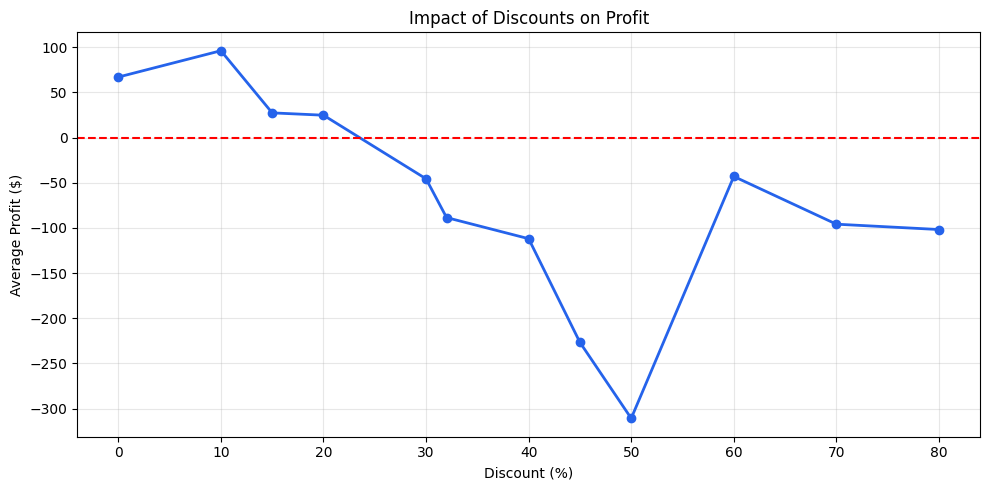

,Average Profit
Discount,
0.00,66.90
0.10,96.06
0.15,27.29
0.20,24.70
0.30,-45.68
0.32,-88.56
0.40,-111.93
0.45,-226.65
0.50,-310.70


In [ ]:
# تحليل تأثير الخصومات على الأرباح

import matplotlib.pyplot as plt

discount_analysis = df.groupby("Discount")["Profit"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    discount_analysis.index * 100,
    discount_analysis.values,
    marker="o",
    color="#2563EB",
    linewidth=2
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Impact of Discounts on Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# عرض النتائج بالأرقام
display(discount_analysis.round(2).to_frame("Average Profit"))

### الاكتشاف الثاني: تأثير الخصومات على الأرباح

بعد تحليل بيانات الخصومات، لاحظت وجود
علاقة بين ارتفاع نسب الخصم وانخفاض متوسط الأرباح.

عند خصم 20% كان متوسط الربح 24.70 دولار،
بينما انخفض إلى خسارة متوسطة قدرها
45.68 دولار عند خصم 30%.

كما وصلت الخسارة المتوسطة إلى 310.70 دولار
عند خصم 50%.

### الاستنتاج
تشير النتائج إلى أن الخصومات المرتفعة
ترتبط بانخفاض الربحية في بيانات المتجر،
وقد تكون أحد العوامل المساهمة في الخسائر.

### التوصية
مراجعة سياسة الخصومات، وخاصة الخصومات
التي تبدأ من 30%، ودراسة ربحية المنتجات
قبل تطبيق خصومات مرتفعة.

,Sales,Profit
Region,,
Central,501239.89,39706.36
East,678781.24,91522.78
South,391721.90,46749.43
West,725457.82,108418.45


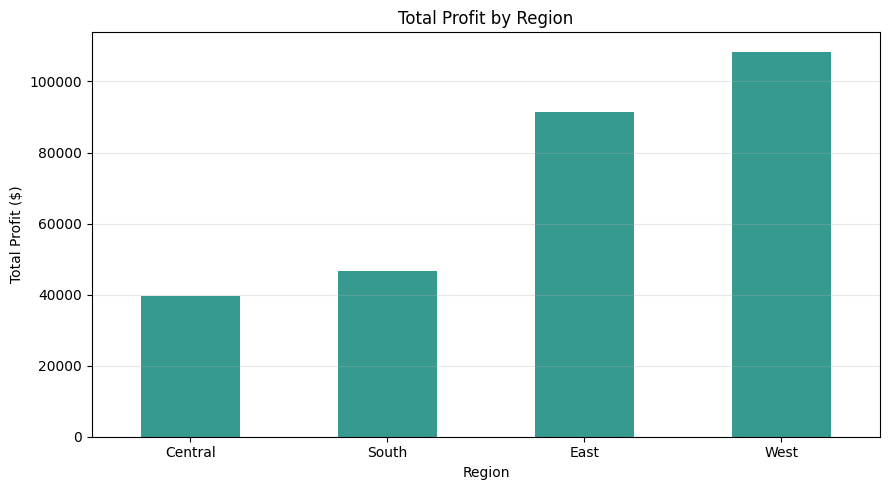

In [ ]:
# تحليل المبيعات والأرباح حسب المنطقة

import matplotlib.pyplot as plt

region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

# عرض النتائج
display(region_analysis.round(2))

# رسم إجمالي الأرباح حسب المنطقة
region_analysis["Profit"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    color="#369A91"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# عرض أرباح المناطق مرتبة من الأقل إلى الأعلى
region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values()
)

display(region_profit.round(2).to_frame("Total Profit ($)"))

,Total Profit ($)
Region,
Central,39706.36
South,46749.43
East,91522.78
West,108418.45


### الاكتشاف الثالث: اختلاف الأرباح بين المناطق

بعد تحليل إجمالي الأرباح حسب المناطق، لاحظت
وجود تفاوت واضح في الأداء.

حققت المنطقة الغربية أعلى إجمالي ربح بقيمة
108,418.45 دولار، تليها المنطقة الشرقية
بقيمة 91,522.78 دولار.

أما المنطقة الجنوبية فحققت 46,749.43 دولار،
بينما سجلت المنطقة الوسطى أقل إجمالي ربح
بقيمة 39,706.36 دولار.

### الاستنتاج
توضح النتائج أن أرباح المتجر تختلف بين المناطق،
وأن المنطقة الوسطى تحتاج إلى دراسة إضافية
لمعرفة أسباب انخفاض أرباحها مقارنة ببقية المناطق.

### التوصية
تحليل المبيعات والخصومات والمنتجات في
المنطقة الوسطى، ومقارنتها بالمناطق الأعلى
ربحية للوصول إلى فرص تحسين الأداء.

In [ ]:
# اكتشاف العمليات التي حققت أكبر خسائر

losses = df[df["Profit"] < 0].copy()

print("عدد السجلات الخاسرة:", len(losses))

print("أكبر 5 عمليات خسارة:")
display(
    losses[
        ["Product Name", "Category", "Region",
         "Sales", "Discount", "Profit"]
    ].sort_values("Profit").head(5)
)

عدد السجلات الخاسرة: 1871
أكبر 5 عمليات خسارة:


,Product Name,Category,Region,Sales,Discount,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Technology,East,4499.985,0.7,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Technology,South,7999.980,0.5,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,Central,2177.584,0.8,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,West,2549.985,0.7,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Office Supplies,Central,1889.990,0.8,-2929.4845


## 4. مفاجآت البيانات

### المفاجأة الأولى: وجود عدد كبير من السجلات الخاسرة

أثناء تحليل البيانات، اكتشفت وجود 1,871 سجلًا
حقق أرباحًا سالبة من أصل 9,994 سجلًا.

- العمود: Profit
- طريقة الاكتشاف: البحث عن القيم الأقل من الصفر.
- القرار المبدئي: الاحتفاظ بهذه السجلات وتحليلها،
لأنها تمثل المشكلة الأساسية للمشروع.

### المفاجأة الثانية: خسارة مرتفعة في أحد المنتجات

لاحظت أن إحدى عمليات بيع طابعة
Cubify CubeX 3D Printer
سجلت خسارة قدرها 6,599.98 دولار،
مع خصم بنسبة 70%.

- الأعمدة: Product Name وProfit وDiscount
- طريقة الاكتشاف: ترتيب السجلات حسب أكبر خسارة.
- القرار المبدئي: مراجعة الخصومات المرتفعة
والمنتجات التي تحقق خسائر كبيرة.

### المفاجأة الثالثة: الخصومات المرتفعة

لاحظت أن أكبر خمس عمليات خسارة ارتبطت
بخصومات تتراوح بين 50% و80%.

- الأعمدة: Discount وProfit
- طريقة الاكتشاف: مقارنة نسب الخصم بالخسائر.
- القرار المبدئي: دراسة العلاقة بين الخصومات
والربحية قبل اقتراح تعديل سياسة التسعير.

### الخلاصة

سأحتفظ بالسجلات الخاسرة خلال مرحلة التحليل،
لأن حذفها قد يؤدي إلى إخفاء المشكلة الفعلية.
وسأستخدم النتائج لاحقًا في تصميم لوحة تحكم
تساعد على متابعة الأرباح والخسائر.

##5. تنظيف البيانات وسجل القرارات

In [ ]:
clean = df.copy()

# نحسب الأسماء اللي فيها مسافات زائدة قبل تعديلها
before = clean["Product Name"]
after = before.str.strip()
changed_names = before.ne(after).sum()
clean["Product Name"] = after

# نوحّد تاريخ الطلب وتاريخ الشحن
for column in ["Order Date", "Ship Date"]:
    clean[column] = pd.to_datetime(clean[column], format="%m/%d/%Y")

print("عدد أسماء المنتجات اللي تعدلت:", changed_names)
print("عدد الصفوف بعد التنظيف:", len(clean))

عدد أسماء المنتجات اللي تعدلت: 16
عدد الصفوف بعد التنظيف: 9994


In [ ]:
from pathlib import Path

missing_rows = df.isna().any(axis=1).sum()
duplicate_rows = df.duplicated().sum()
matching_rows = df.drop(columns="Row ID").duplicated(keep=False).sum()
loss_rows = (clean["Profit"] < 0).sum()
worst_loss = clean.nsmallest(1, "Profit").iloc[0]
top_losses = clean.nsmallest(5, "Profit")

decision_log = pd.DataFrame([
    ["مسافات زائدة في أسماء المنتجات", "إزالة المسافات من البداية والنهاية",
     f"تعدّل الاسم في {changed_names} سجلًا", changed_names],

    ["تنسيق التواريخ", "توحيد تاريخ الطلب والشحن",
     f"تم تحويل التاريخين في {len(clean):,} سجلًا", len(clean)],

    ["القيم المفقودة", "لا حاجة للتعبئة",
     f"عدد الخلايا الناقصة {df.isna().sum().sum()}", missing_rows],

    ["التكرار الكامل", "الاحتفاظ بالصفوف",
     f"عدد الصفوف المكررة بالكامل {duplicate_rows}", duplicate_rows],

    ["بنود تتطابق باستثناء معرّف الصف", "الاحتفاظ بها لحين مراجعة المصدر",
     f"{matching_rows} بندين بتفاصيل متطابقة ومعرّفين مختلفين", matching_rows],

    ["السجلات الخاسرة", "الاحتفاظ بها لتحليل الخسائر",
     f"{loss_rows:,} سجلًا خاسرًا من أصل {len(clean):,}", loss_rows],

    ["أكبر خسارة", "الاحتفاظ بالسجل للتحليل",
     f"خسارة {abs(worst_loss['Profit']):,.2f} دولار عند خصم {worst_loss['Discount']:.0%}", 1],

    ["خصومات أكبر خمس خسائر", "الاحتفاظ بقيم الخصم للمقارنة",
     f"تراوحت بين {top_losses['Discount'].min():.0%} و{top_losses['Discount'].max():.0%}",
     len(top_losses)],
], columns=["المشكلة", "القرار", "السبب بالأرقام", "الصفوف المعنية"])

display(decision_log)

Path("data").mkdir(exist_ok=True)
clean.to_csv("data/clean.csv", index=False)

print(f"تم حفظ data/clean.csv — {len(clean):,} صفًا و{clean.shape[1]} عمودًا")

,المشكلة,القرار,السبب بالأرقام,الصفوف المعنية
0,مسافات زائدة في أسماء المنتجات,إزالة المسافات من البداية والنهاية,تعدّل الاسم في 16 سجلًا,16
1,تنسيق التواريخ,توحيد تاريخ الطلب والشحن,"تم تحويل التاريخين في 9,994 سجلًا",9994
2,القيم المفقودة,لا حاجة للتعبئة,عدد الخلايا الناقصة 0,0
3,التكرار الكامل,الاحتفاظ بالصفوف,عدد الصفوف المكررة بالكامل 0,0
4,بنود تتطابق باستثناء معرّف الصف,الاحتفاظ بها لحين مراجعة المصدر,2 بندين بتفاصيل متطابقة ومعرّفين مختلفين,2
5,السجلات الخاسرة,الاحتفاظ بها لتحليل الخسائر,"1,871 سجلًا خاسرًا من أصل 9,994",1871
6,أكبر خسارة,الاحتفاظ بالسجل للتحليل,"خسارة 6,599.98 دولار عند خصم 70%",1
7,خصومات أكبر خمس خسائر,الاحتفاظ بقيم الخصم للمقارنة,تراوحت بين 50% و80%,5


تم حفظ data/clean.csv — 9,994 صفًا و21 عمودًا


## ٦. إنشاء أعمدة جديدة

أضفت ثلاثة أعمدة من بيانات الطلب والشحن لدراسة علاقتها بمتوسط الربح:

- **سنة الطلب** لمقارنة متوسط الربح بين السنوات.
- **شهر الطلب** لمعرفة الأشهر اللي سجّلت متوسط ربح أعلى.
- **أيام الشحن** لحساب المدة من تاريخ الطلب إلى تاريخ الشحن ومقارنة متوسط الربح حسب هذه المدة.

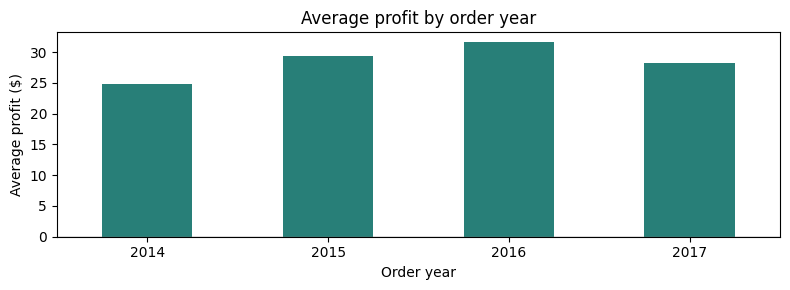

أضفت سنة الطلب لمقارنة الربح بين السنوات.
أعلى متوسط ربح كان عند القيمة 2016 وبلغ 31.62 دولار.


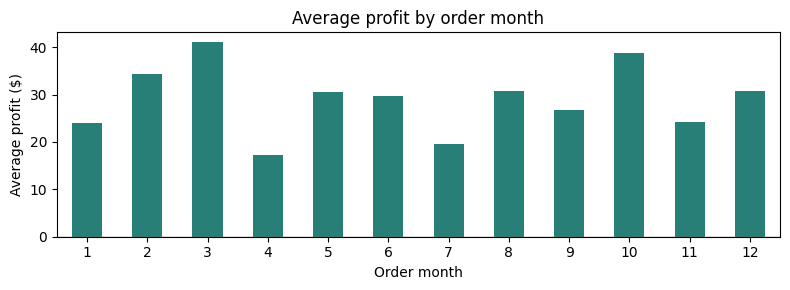

أضفت شهر الطلب لمقارنة الربح بين الأشهر.
أعلى متوسط ربح كان عند القيمة 3 وبلغ 41.08 دولار.


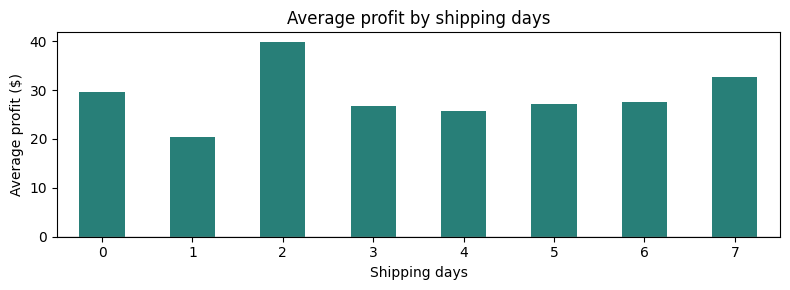

أضفت أيام الشحن لمقارنة الربح حسب المدة من الطلب إلى الشحن.
أعلى متوسط ربح كان عند القيمة 2 وبلغ 39.82 دولار.


In [ ]:
import matplotlib.pyplot as plt

features = clean.copy()

features["Order_Year"] = features["Order Date"].dt.year
features["Order_Month"] = features["Order Date"].dt.month
features["Shipping_Days"] = (
    features["Ship Date"] - features["Order Date"]
).dt.days

new_columns = [
    ("Order_Year", "Order year", "سنة الطلب", "لمقارنة الربح بين السنوات"),
    ("Order_Month", "Order month", "شهر الطلب", "لمقارنة الربح بين الأشهر"),
    ("Shipping_Days", "Shipping days", "أيام الشحن", "لمقارنة الربح حسب المدة من الطلب إلى الشحن"),
]

for column, axis_label, name, reason in new_columns:
    average_profit = features.groupby(column)["Profit"].mean()

    ax = average_profit.plot.bar(figsize=(8, 3), color="#287F78", rot=0)
    ax.set_title(f"Average profit by {axis_label.lower()}")
    ax.set_xlabel(axis_label)
    ax.set_ylabel("Average profit ($)")
    ax.axhline(0, color="gray", linewidth=1)
    plt.tight_layout()
    plt.show()

    best = average_profit.idxmax()
    print(f"أضفت {name} {reason}.")
    print(f"أعلى متوسط ربح كان عند القيمة {best} وبلغ {average_profit.loc[best]:.2f} دولار.")

## ٧. اختيار الأعمدة

راجعت الأعمدة وحددت وش أحتفظ فيه ووش أستبعده، مع توضيح سبب كل قرار بالأرقام. احتفظت بعمود الربح `Profit` في الملف بصفته المتغير المستهدف.

,العمود,القرار,السبب,الدليل بالأرقام
0,Row ID,استبعاد,معرّف فريد لكل صف,"9,994 قيمة مختلفة"
1,Order ID,استبعاد,معرّف لتجميع بنود الطلب,"5,009 قيمة مختلفة"
2,Order Date,استبعاد,لخّصته بسنة الطلب وشهره,"1,237 قيمة مختلفة"
3,Ship Date,استبعاد,استخدمته لحساب أيام الشحن,"1,334 قيمة مختلفة"
4,Ship Mode,احتفاظ,يميز طرق الشحن,4 قيمة مختلفة
5,Customer ID,استبعاد,معرّف للعميل، وأبقيت شريحة العميل,793 قيمة مختلفة
6,Customer Name,استبعاد,اسم العميل، وأبقيت شريحة العميل,793 قيمة مختلفة
7,Segment,احتفاظ,يميز شرائح العملاء,3 قيمة مختلفة
8,Country,استبعاد,جميع السجلات من بلد واحد,1 قيمة مختلفة
9,City,استبعاد,أبقيت الولاية والمنطقة للمقارنة الجغرافية,531 قيمة مختلفة


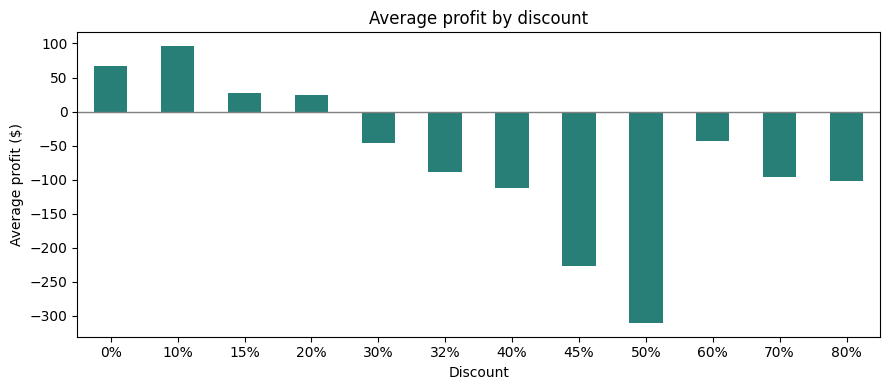

تم حفظ data/model_ready.csv — 9,994 صفًا و13 عمودًا


In [ ]:
keep = {
    "Ship Mode": "يميز طرق الشحن",
    "Segment": "يميز شرائح العملاء",
    "State": "يوضح الفروق بين الولايات",
    "Region": "يسهّل المقارنة بين المناطق",
    "Category": "يميز فئات المنتجات الرئيسية",
    "Sub-Category": "يوفر تفاصيل عن نوع المنتج داخل الفئة",
    "Sales": "يوضح قيمة المبيعات لكل بند",
    "Quantity": "يوضح عدد الوحدات المباعة",
    "Discount": "يوضح نسبة الخصم وعلاقتها بمتوسط الربح",
    "Order_Year": "يساعد على مقارنة الربح بين السنوات",
    "Order_Month": "يساعد على مقارنة الربح بين الأشهر",
    "Shipping_Days": "يوضح المدة بين الطلب والشحن",
}

drop = {
    "Row ID": "معرّف فريد لكل صف",
    "Order ID": "معرّف لتجميع بنود الطلب",
    "Order Date": "لخّصته بسنة الطلب وشهره",
    "Ship Date": "استخدمته لحساب أيام الشحن",
    "Customer ID": "معرّف للعميل، وأبقيت شريحة العميل",
    "Customer Name": "اسم العميل، وأبقيت شريحة العميل",
    "Country": "جميع السجلات من بلد واحد",
    "City": "أبقيت الولاية والمنطقة للمقارنة الجغرافية",
    "Postal Code": "أبقيت الولاية والمنطقة للمقارنة الجغرافية",
    "Product ID": "معرّف للمنتج، وأبقيت الفئة والفئة الفرعية",
    "Product Name": "أبقيت الفئة والفئة الفرعية لتلخيص نوع المنتج",
}

discount_profit = features.groupby("Discount")["Profit"].mean()
rows = []

for column in features.columns:
    evidence = f"{features[column].nunique():,} قيمة مختلفة"

    if column == "Profit":
        decision, reason = "احتفاظ كهدف", "الربح لكل بند بيع"
    elif column in keep:
        decision, reason = "احتفاظ", keep[column]
        if column == "Discount":
            evidence += (
                f". متوسط الربح {discount_profit.loc[0]:.2f} دولار بدون خصم، "
                f"و{discount_profit.loc[0.30]:.2f} دولار عند خصم 30%"
            )
    else:
        decision, reason = "استبعاد", drop[column]

    rows.append([column, decision, reason, evidence])

selection_table = pd.DataFrame(
    rows, columns=["العمود", "القرار", "السبب", "الدليل بالأرقام"]
)
display(selection_table)

ax = discount_profit.plot.bar(figsize=(9, 4), color="#287F78", rot=0)
ax.set_title("Average profit by discount")
ax.set_xlabel("Discount")
ax.set_ylabel("Average profit ($)")
ax.set_xticklabels([f"{value:.0%}" for value in discount_profit.index])
ax.axhline(0, color="gray", linewidth=1)
plt.tight_layout()
plt.show()

model_ready = features[list(keep) + ["Profit"]]
model_ready.to_csv("data/model_ready.csv", index=False)
print(f"تم حفظ data/model_ready.csv — {len(model_ready):,} صفًا و{model_ready.shape[1]} عمودًا")

## 8. الاكتشافات

,Product Name,Sales,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08
786,HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
686,GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
805,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
813,High Speed Automatic Electric Letter Opener,17030.31,-262.00


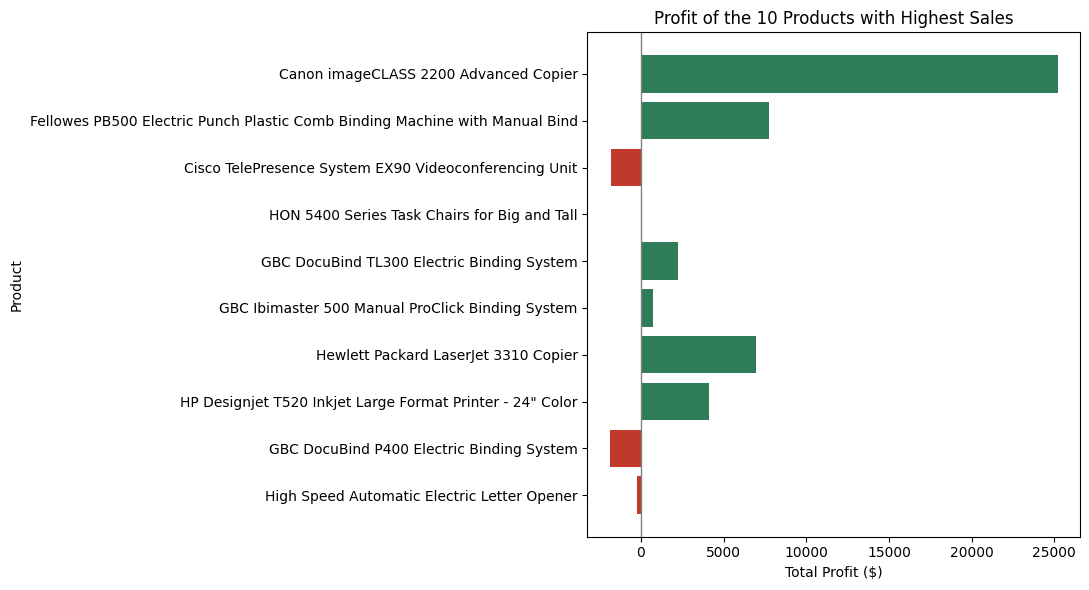

In [2]:
import matplotlib.pyplot as plt

top_products = (
    clean_df.groupby("Product Name", as_index=False)[["Sales", "Profit"]]
    .sum()
    .nlargest(10, "Sales")
)

display(top_products.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
colors = [
    "#c0392b" if profit < 0 else "#2e7d58"
    for profit in top_products["Profit"]
]

ax.barh(top_products["Product Name"], top_products["Profit"], color=colors)
ax.axvline(0, color="gray", linewidth=1)
ax.invert_yaxis()
ax.set_title("Profit of the 10 Products with Highest Sales")
ax.set_xlabel("Total Profit ($)")
ax.set_ylabel("Product")
plt.tight_layout()
plt.show()

### الاكتشاف الأول: بعض المنتجات الأعلى مبيعًا سجلت خسارة

سجلت 3 من أعلى 10 منتجات مبيعًا خسارة. مثلًا، بلغت مبيعات جهاز GBC DocuBind P400 نحو 17,965.07 دولار، وسجّل خسارة قدرها 1,878.17 دولار.

**ماذا يعني للعميل؟** يتابع ربح كل منتج إلى جانب مبيعاته، ويبدأ بمراجعة سعر وخصومات جهاز GBC DocuBind P400.

,Sales,Profit,Margin (%)
Discount,,,
0.00,1087908.47,320987.60,29.51
0.10,54369.35,9029.18,16.61
0.15,27558.52,1418.99,5.15
0.20,764594.37,90337.31,11.82
0.30,103226.66,-10369.28,-10.05
0.32,14493.46,-2391.14,-16.50
0.40,116417.78,-23057.05,-19.81
0.45,5484.97,-2493.11,-45.45
0.50,58918.54,-20506.43,-34.80


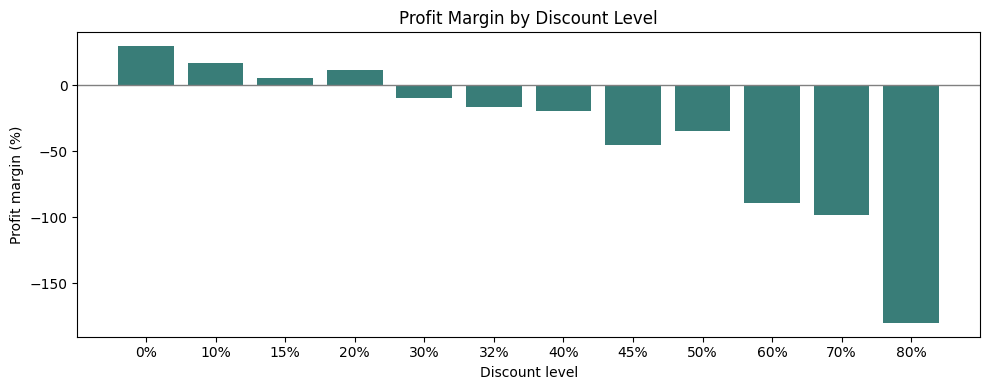

In [3]:
import matplotlib.pyplot as plt

discount_summary = (
    clean_df.groupby("Discount")[["Sales", "Profit"]]
    .sum()
    .sort_index()
)

discount_summary["Margin (%)"] = (
    100 * discount_summary["Profit"] / discount_summary["Sales"]
)

display(discount_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
discount_labels = [f"{rate:.0%}" for rate in discount_summary.index]

ax.bar(discount_labels, discount_summary["Margin (%)"], color="#397d78")
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Profit Margin by Discount Level")
ax.set_xlabel("Discount level")
ax.set_ylabel("Profit margin (%)")

plt.tight_layout()
plt.show()

### الاكتشاف الثاني: هامش الربح كان سالبًا عند الخصومات من 30% فأعلى

بلغ هامش الربح 11.82% عند خصم 20%، بينما بلغ ‎-10.05% عند خصم 30% و‎-19.81% عند خصم 40%. وفي البيانات، كان الهامش سالبًا عند كل مستوى خصم مسجّل من 30% فأعلى.

**ماذا يعني للعميل؟** يراجع العروض بخصم 30% فأعلى، ويحسب هامش الربح المتوقع لكل منتج قبل اعتماد الخصم.

,Sales,Profit,Margin (%)
Region,,,
West,725457.82,108418.45,14.94
East,678781.24,91522.78,13.48
South,391721.90,46749.43,11.93
Central,501239.89,39706.36,7.92


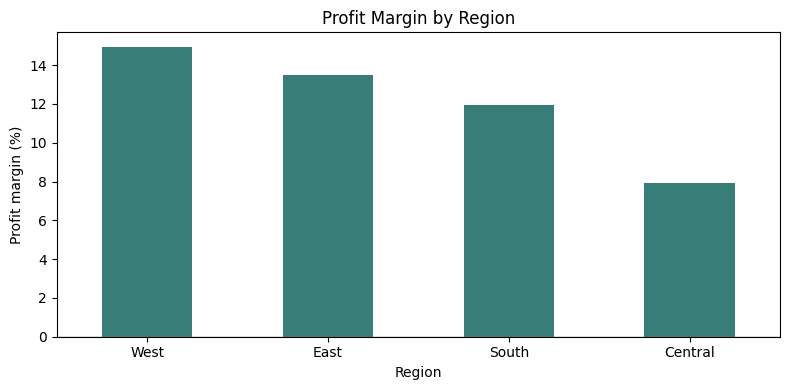

In [4]:
region_summary = clean_df.groupby("Region")[["Sales", "Profit"]].sum()
region_summary["Margin (%)"] = (
    100 * region_summary["Profit"] / region_summary["Sales"]
)
region_summary = region_summary.sort_values("Margin (%)", ascending=False)

display(region_summary.round(2))

ax = region_summary["Margin (%)"].plot(
    kind="bar", color="#397d78", figsize=(8, 4), rot=0
)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Profit Margin by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Profit margin (%)")
plt.tight_layout()
plt.show()

### الاكتشاف الثالث: المنطقة الغربية حققت أعلى هامش ربح

بلغ هامش الربح في المنطقة الغربية 14.94%، مقابل 7.92% في المنطقة الوسطى، بفارق 7.02 نقاط مئوية. وحققت المنطقة الوسطى مبيعات بلغت 501,239.89 دولار، لكنها سجلت أقل هامش ربح بين المناطق الأربع.

**ماذا يعني للعميل؟** يبدأ بمراجعة المنتجات والخصومات في المنطقة الوسطى لمعرفة أيها يسهم في انخفاض هامش الربح.

,Sales,Profit
Sub-Category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10
Fasteners,3024.28,949.52
Machines,189238.63,3384.76
Labels,12486.31,5546.25
Art,27118.79,6527.79
Envelopes,16476.40,6964.18
Furnishings,91705.16,13059.14


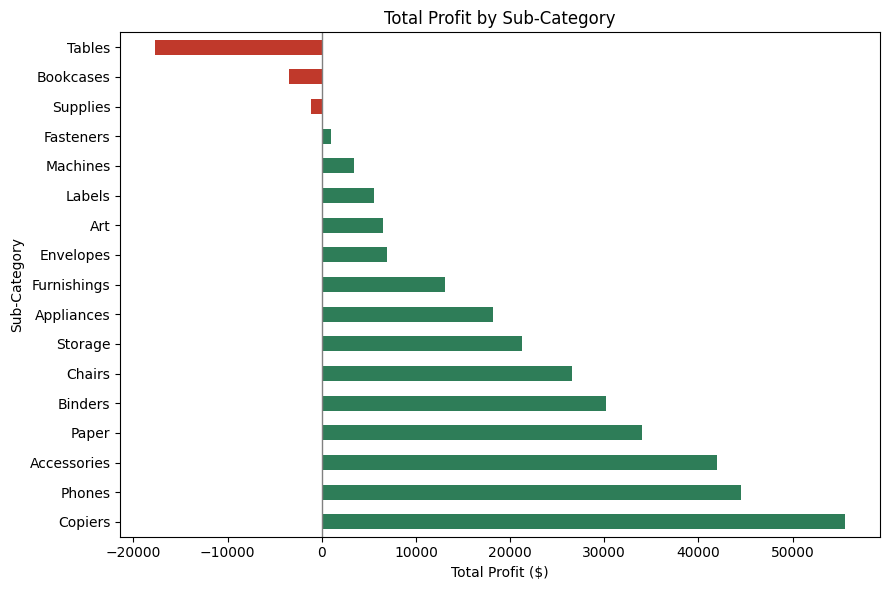

In [5]:
subcategory_summary = (
    clean_df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Profit")
)

display(subcategory_summary.round(2))

colors = [
    "#c0392b" if profit < 0 else "#2e7d58"
    for profit in subcategory_summary["Profit"]
]

ax = subcategory_summary["Profit"].plot(
    kind="barh", color=colors, figsize=(9, 6)
)
ax.invert_yaxis()
ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Total Profit by Sub-Category")
ax.set_xlabel("Total Profit ($)")
ax.set_ylabel("Sub-Category")
plt.tight_layout()
plt.show()

### الاكتشاف الرابع — الطاولات سجّلت أكبر خسارة بين الفئات الفرعية

سجّلت ثلاث فئات فرعية خسارة إجمالية: الطاولات، وخزائن الكتب، والمستلزمات. وكانت الطاولات الأكثر خسارة، بينما حققت فئة آلات التصوير أعلى ربح، بقيمة 55,617.82 دولار.

**ماذا يعني للعميل؟** يبدأ بمراجعة منتجات الطاولات لمعرفة أيها يسهم أكثر في خسارة الفئة، ثم يراجع أسعارها وخصوماتها.

,Order_Lines,Sales,Profit
Discount,,,
0.0,1,5443.96,2504.22
0.2,2,7621.54,2477.00
0.7,1,1633.19,-1306.55
0.8,2,3266.38,-5552.84


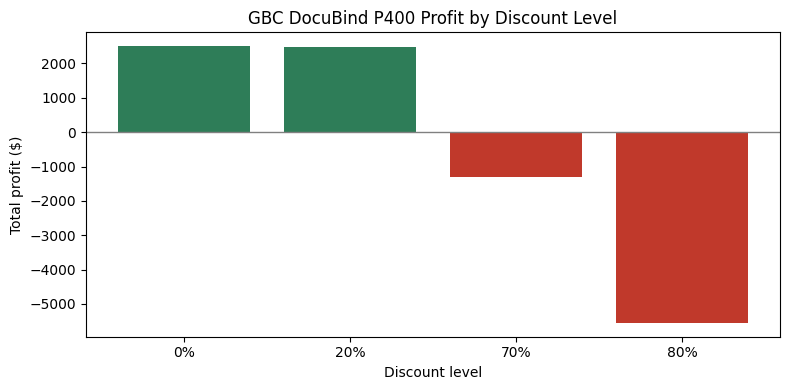

In [6]:
p400_rows = clean_df[
    clean_df["Product Name"].str.contains("GBC DocuBind P400", regex=False, na=False)
]

p400_summary = p400_rows.groupby("Discount").agg(
    Order_Lines=("Profit", "size"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).sort_index()

display(p400_summary.round(2))

labels = [f"{rate:.0%}" for rate in p400_summary.index]
colors = [
    "#c0392b" if profit < 0 else "#2e7d58"
    for profit in p400_summary["Profit"]
]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, p400_summary["Profit"], color=colors)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("GBC DocuBind P400 Profit by Discount Level")
ax.set_xlabel("Discount level")
ax.set_ylabel("Total profit ($)")
plt.tight_layout()
plt.show()

### الاكتشاف الخامس — جهاز GBC DocuBind P400 سجّل خسارة عند أعلى خصمين

حقق الجهاز ربحًا قدره 2,504.22 دولار بدون خصم و2,477.00 دولار عند خصم 20%. وسجّل خسارة قدرها 1,306.55 دولار عند خصم 70% و5,552.84 دولار عند خصم 80%.

**ماذا يعني للعميل؟** يراجع العروض على هذا الجهاز، خصوصًا خصمي 70% و80%، ويحسب هامش الربح المتوقع قبل تكرارها.

### إجابة سؤال العميل

بعض المنتجات تحقق مبيعات مرتفعة ومع ذلك تسجّل خسارة. جهاز GBC DocuBind P400 مثلًا حقق مبيعات بقيمة 17,965.07 دولار، وسجّل خسارة إجمالية قدرها 1,878.17 دولار. في بيانات الجهاز، بلغت خسائر بنود البيع عند خصمي 70% و80% معًا 6,859.39 دولار، وتجاوزت الأرباح المحققة عند البيع بدون خصم وعند خصم 20%.

## 9. التوصيات

1. **متابعة ربح المنتجات الأعلى مبيعًا.** أضف إجمالي الربح وهامش الربح إلى تقرير المبيعات لكل منتج، وراجع المنتجات الخاسرة أولًا. سجّلت 3 من أعلى 10 منتجات مبيعًا خسارة.
2. **مراجعة الخصومات الكبيرة قبل اعتمادها.** احسب هامش الربح المتوقع للمنتج عند السعر المخفّض. بلغ هامش الربح الإجمالي عند خصم 30% نحو سالب 10.05%، مقابل موجب 11.82% عند خصم 20%.
3. **البدء بالمنطقة الوسطى.** راجع المنتجات والخصومات فيها حسب الفئة، لأن هامش ربحها بلغ 7.92%، وهو الأقل بين المناطق الأربع، مقابل 14.94% في المنطقة الغربية.

**حدود التحليل:** تظهر البيانات ارتباطًا بين الخصومات الكبيرة والخسارة، ولا تكفي لإثبات أن الخصم وحده سبّب الخسارة.

In [7]:
%%writefile app.py
from pathlib import Path

import pandas as pd
import streamlit as st

st.set_page_config(page_title="تحليل أرباح المبيعات", layout="wide")
st.title("لوحة تحليل أرباح المبيعات")


@st.cache_data
def load_data():
    csv_path = Path(__file__).resolve().parent / "data" / "clean.csv"
    return pd.read_csv(csv_path)


try:
    data = load_data()
except FileNotFoundError:
    st.error("ضعي clean.csv داخل مجلد data بجانب ملف app.py.")
    st.stop()

st.sidebar.header("الفلاتر")

regions = sorted(data["Region"].dropna().unique())
categories = sorted(data["Category"].dropna().unique())

selected_regions = st.sidebar.multiselect("المنطقة", regions, default=regions)
selected_categories = st.sidebar.multiselect("الفئة", categories, default=categories)
max_discount = st.sidebar.slider("أقصى خصم (%)", 0, 100, 100)

filtered = data[
    data["Region"].isin(selected_regions)
    & data["Category"].isin(selected_categories)
    & (data["Discount"] <= max_discount / 100)
]

sales = filtered["Sales"].sum()
profit = filtered["Profit"].sum()
margin = f"{100 * profit / sales:.2f}%" if sales else "—"

sales_col, profit_col, margin_col, orders_col = st.columns(4)
sales_col.metric("إجمالي المبيعات", f"${sales:,.2f}")
profit_col.metric("إجمالي الربح", f"${profit:,.2f}")
margin_col.metric("هامش الربح", margin)
orders_col.metric("عدد الطلبات", f'{filtered["Order ID"].nunique():,}')

if filtered.empty:
    st.info("ما فيه بيانات للفلاتر الحالية. غيّري الاختيارات لعرض الرسوم.")
    st.stop()

st.subheader("ربح أعلى 10 منتجات مبيعًا")
products = filtered.groupby("Product Name")[["Sales", "Profit"]].sum()
top_products = products.nlargest(10, "Sales")
st.bar_chart(top_products["Profit"], x_label="المنتج", y_label="الربح ($)")

st.subheader("هامش الربح حسب الخصم")
discounts = filtered.groupby("Discount")[["Sales", "Profit"]].sum()
discounts = discounts.loc[discounts["Sales"] != 0].copy()
discounts["Margin (%)"] = 100 * discounts["Profit"] / discounts["Sales"]
discounts.index = discounts.index.map(lambda rate: f"{rate:.0%}")
st.bar_chart(discounts["Margin (%)"], x_label="الخصم", y_label="هامش الربح (%)")

st.subheader("هامش الربح حسب المنطقة")
regional = filtered.groupby("Region")[["Sales", "Profit"]].sum()
regional = regional.loc[regional["Sales"] != 0].copy()
regional["Margin (%)"] = 100 * regional["Profit"] / regional["Sales"]
st.bar_chart(regional["Margin (%)"], x_label="المنطقة", y_label="هامش الربح (%)")

Writing app.py
